# Week 11 Instructor Demo: Prompting, Post-Training & Reasoning

Welcome to the demonstration notebook for Week 11! In this notebook, we will interactively explore the pillars that turn a raw pretrained language model into a useful, aligned, and reasoning-capable assistant:

1. **Prompt Engineering Mechanics:** How system prompts, delimiters, and structured output formatting work under the hood. Zero-shot vs. few-shot vs. Chain-of-Thought prompting.
2. **Base Model vs. Aligned Model:** Loading a base model and its instruction-tuned counterpart side-by-side, observing the dramatic behavioral difference, and understanding chat templates.
3. **DPO Loss from Scratch:** Implementing the Direct Preference Optimization loss function in raw PyTorch — no black boxes.
4. **GRPO Conceptual Demo:** A toy illustration of Group Relative Policy Optimization reward computation.

**Anti-Black-Box Rule:** We will look inside every API call and understand the tensor shapes flowing through.

## Environment Setup

We install the necessary libraries. We use `transformers` for model loading and `torch` for tensor manipulation. Ensure you are running on a **GPU runtime** (T4 is sufficient) in Colab.

In [1]:
# !pip install -q transformers accelerate torch

In [2]:
import torch
import torch.nn.functional as F
import json
import re
import textwrap
from transformers import AutoModelForCausalLM, AutoTokenizer

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"Total VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
elif torch.backends.mps.is_available():
    print("MPS (Apple Silicon) Available: True")
else:
    print("WARNING: No GPU detected. We will use CPU with pre-computed outputs as fallback.")

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {DEVICE}")

PyTorch version: 2.13.0
CUDA Available: False
MPS (Apple Silicon) Available: True
Using device: mps


---
## Section 1: Prompt Engineering Mechanics

Before we touch any model, let's understand what "prompting" actually means at the token level. A prompt is just a string that gets tokenized into integer IDs and fed into the model. The art of prompt engineering is about crafting that string to steer the model's probability distribution toward the outputs we want.

### Key Concepts:
- **System Prompt:** Sets the model's persona and constraints (only works with instruction-tuned models).
- **Delimiters:** Triple backticks, XML tags, etc. that help the model distinguish between instructions and content.
- **Zero-shot:** No examples provided — just the instruction.
- **Few-shot:** 1–5 input-output examples provided before the actual query.
- **Chain-of-Thought (CoT):** Explicitly ask the model to "think step by step" before answering.

### 1.1 Understanding Chat Templates

Modern instruction-tuned models expect input in a specific **chat template** format. This is NOT just a convention — the model was literally trained on text formatted this way. If you send raw text to an instruct model, it won't know where the system prompt ends and the user query begins.

Let's see what a chat template looks like for Qwen2.5:

In [3]:
# Load the instruct tokenizer to inspect its chat template
tokenizer_instruct = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")

# Define a conversation in the standard OpenAI-style messages format
messages = [
    {"role": "system", "content": "You are a helpful assistant that responds in JSON format."},
    {"role": "user", "content": "What is the capital of France?"}
]

# apply_chat_template converts the messages list into the model's expected string format
formatted_prompt = tokenizer_instruct.apply_chat_template(
    messages,
    tokenize=False,         # Return the string, not token IDs
    add_generation_prompt=True  # Add the assistant turn prefix so the model starts generating
)

print("=== Formatted Prompt (what the model actually sees) ===")
print(formatted_prompt)
print()

# Now tokenize it and inspect the token IDs
token_ids = tokenizer_instruct.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_dict=False)
if isinstance(token_ids, dict):
    token_ids = token_ids["input_ids"]
if len(token_ids) > 0 and isinstance(token_ids[0], list):
    token_ids = token_ids[0]

print(f"Number of tokens: {len(token_ids)}")
print(f"First 20 token IDs: {token_ids[:20]}")
print(f"Decoded tokens:")
for i, tid in enumerate(token_ids[:20]):
    print(f"  [{i}] ID={tid:6d} -> '{tokenizer_instruct.decode([tid])}'")


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

=== Formatted Prompt (what the model actually sees) ===
<|im_start|>system
You are a helpful assistant that responds in JSON format.<|im_end|>
<|im_start|>user
What is the capital of France?<|im_end|>
<|im_start|>assistant


Number of tokens: 31
First 20 token IDs: [151644, 8948, 198, 2610, 525, 264, 10950, 17847, 429, 30580, 304, 4718, 3561, 13, 151645, 198, 151644, 872, 198, 3838]
Decoded tokens:
  [0] ID=151644 -> '<|im_start|>'
  [1] ID=  8948 -> 'system'
  [2] ID=   198 -> '
'
  [3] ID=  2610 -> 'You'
  [4] ID=   525 -> ' are'
  [5] ID=   264 -> ' a'
  [6] ID= 10950 -> ' helpful'
  [7] ID= 17847 -> ' assistant'
  [8] ID=   429 -> ' that'
  [9] ID= 30580 -> ' responds'
  [10] ID=   304 -> ' in'
  [11] ID=  4718 -> ' JSON'
  [12] ID=  3561 -> ' format'
  [13] ID=    13 -> '.'
  [14] ID=151645 -> '<|im_end|>'
  [15] ID=   198 -> '
'
  [16] ID=151644 -> '<|im_start|>'
  [17] ID=   872 -> 'user'
  [18] ID=   198 -> '
'
  [19] ID=  3838 -> 'What'


### 1.2 Prompt Strategy Comparison

Let's compare three prompting strategies on the same task: **Sentiment Classification** of a movie review.

We'll define the prompts as raw strings first, then send them to the model.

In [4]:
# The text we want to classify
review_text = """The cinematography was breathtaking but the plot felt rushed 
and the character development was nearly nonexistent. I left the theater 
feeling conflicted — visually stunning but emotionally hollow."""

# ---- Strategy 1: Zero-Shot ----
zero_shot_messages = [
    {"role": "system", "content": "You are a sentiment classifier. Respond with exactly one word: positive, negative, or mixed."},
    {"role": "user", "content": f"Classify the sentiment of this review:\n\n{review_text}"}
]

# ---- Strategy 2: Few-Shot ----
few_shot_messages = [
    {"role": "system", "content": "You are a sentiment classifier. Respond with exactly one word: positive, negative, or mixed."},
    {"role": "user", "content": "Classify: 'This movie was absolutely fantastic, I loved every minute!'"},
    {"role": "assistant", "content": "positive"},
    {"role": "user", "content": "Classify: 'Terrible acting, boring plot, waste of time.'"},
    {"role": "assistant", "content": "negative"},
    {"role": "user", "content": "Classify: 'Great visuals but the story was weak and predictable.'"},
    {"role": "assistant", "content": "mixed"},
    {"role": "user", "content": f"Classify: '{review_text}'"}
]

# ---- Strategy 3: Chain-of-Thought ----
cot_messages = [
    {"role": "system", "content": """You are a sentiment classifier. First, think step by step:
1. List the positive aspects mentioned.
2. List the negative aspects mentioned.
3. Weigh them against each other.
4. Give your final classification as: positive, negative, or mixed.

Format your response as:
Positives: ...
Negatives: ...
Reasoning: ...
Classification: [your answer]"""},
    {"role": "user", "content": f"Classify the sentiment of this review:\n\n{review_text}"}
]

# Let's see how each prompt looks when formatted
for name, msgs in [("Zero-Shot", zero_shot_messages), ("Few-Shot", few_shot_messages), ("CoT", cot_messages)]:
    formatted = tokenizer_instruct.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    token_count = len(tokenizer_instruct(formatted)["input_ids"])  # tokenize the formatted string (apply_chat_template(tokenize=True) returns a dict in recent transformers)
    print(f"\n{'='*60}")
    print(f"Strategy: {name} | Token Count: {token_count}")
    print(f"{'='*60}")
    print(formatted[:500] + "..." if len(formatted) > 500 else formatted)


Strategy: Zero-Shot | Token Count: 75
<|im_start|>system
You are a sentiment classifier. Respond with exactly one word: positive, negative, or mixed.<|im_end|>
<|im_start|>user
Classify the sentiment of this review:

The cinematography was breathtaking but the plot felt rushed 
and the character development was nearly nonexistent. I left the theater 
feeling conflicted — visually stunning but emotionally hollow.<|im_end|>
<|im_start|>assistant


Strategy: Few-Shot | Token Count: 148
<|im_start|>system
You are a sentiment classifier. Respond with exactly one word: positive, negative, or mixed.<|im_end|>
<|im_start|>user
Classify: 'This movie was absolutely fantastic, I loved every minute!'<|im_end|>
<|im_start|>assistant
positive<|im_end|>
<|im_start|>user
Classify: 'Terrible acting, boring plot, waste of time.'<|im_end|>
<|im_start|>assistant
negative<|im_end|>
<|im_start|>user
Classify: 'Great visuals but the story was weak and predictable.'<|im_end|>
<|im_start|>assistant...

Strate

### 1.3 Running the Prompts Through the Model

Now let's actually generate outputs from the instruct model with each strategy. We load the model in float16 to fit on a T4 GPU.

In [5]:
# Load the instruct model (0.5B is tiny — fits on any GPU and even CPU)
model_instruct = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct",
    torch_dtype=torch.float16 if DEVICE in ["cuda", "mps"] else torch.float32,
    device_map="auto" if DEVICE == "cuda" else None
)
if DEVICE in ["cpu", "mps"]:
    model_instruct = model_instruct.to(DEVICE)

print(f"Model loaded. Parameters: {sum(p.numel() for p in model_instruct.parameters()) / 1e6:.1f}M")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded. Parameters: 494.0M


In [6]:
def generate_from_messages(model, tokenizer, messages, max_new_tokens=200):
    """
    Full manual generation pipeline — NO pipeline() API!
    
    Steps:
    1. Apply chat template to format the messages string
    2. Tokenize the formatted string into input_ids tensor
    3. Send to model.generate()
    4. Decode only the NEW tokens (exclude the prompt)
    """
    # Step 1: Format using chat template
    formatted = tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    
    # Step 2: Tokenize
    inputs = tokenizer(formatted, return_tensors="pt").to(model.device)
    prompt_length = inputs["input_ids"].shape[1]  # Shape: [1, seq_len]
    
    # Step 3: Generate Manually (Anti-Black-Box Policy)
    input_ids = inputs["input_ids"]
    attention_mask = inputs["attention_mask"]
    
    with torch.no_grad():
        for _ in range(max_new_tokens):
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            # Get logits for the last generated token
            next_token_logits = outputs.logits[:, -1, :]
            # Greedy decoding (argmax)
            next_token_id = torch.argmax(next_token_logits, dim=-1).unsqueeze(0)
            
            # Stop if the model outputs the EOS token
            if next_token_id.item() == tokenizer.eos_token_id:
                break
                
            # Concatenate the new token to the sequence
            input_ids = torch.cat([input_ids, next_token_id], dim=-1)
            attention_mask = torch.cat([attention_mask, torch.ones((1, 1), device=model.device)], dim=-1)
    
    # Step 4: Decode only the generated part (exclude prompt tokens)
    generated_ids = input_ids[0, prompt_length:]  # Shape: [generated_len]
    response = tokenizer.decode(generated_ids, skip_special_tokens=True)
    
    return response

# Generate for each strategy
strategies = {
    "Zero-Shot": zero_shot_messages,
    "Few-Shot": few_shot_messages,
    "Chain-of-Thought": cot_messages
}

print("Generating responses for each prompting strategy...\n")
for name, msgs in strategies.items():
    response = generate_from_messages(model_instruct, tokenizer_instruct, msgs)
    print(f"{'='*60}")
    print(f"Strategy: {name}")
    print(f"{'='*60}")
    print(response.strip())
    print()

Generating responses for each prompting strategy...

Strategy: Zero-Shot
mixed

Strategy: Few-Shot
negative

Strategy: Chain-of-Thought
Positives: The cinematography was breathtaking
Reasoning: The reviewer mentions that the cinematography was "breathtaking," which is a positive sentiment.
Negatives: The plot felt rushed
Reasoning: The reviewer states that the plot felt "rushed, " which is a negative sentiment.
Classification: Mixed



### 1.4 Key Takeaway on Prompting

Notice the difference:
- **Zero-shot** often works for simple tasks but may be unreliable for nuanced ones.
- **Few-shot** provides calibration examples that dramatically improve consistency.
- **Chain-of-Thought** forces the model to allocate compute (tokens) to the reasoning process, improving accuracy on complex tasks.

The cost is **token count** — more tokens = more latency and cost. This is a fundamental prompt engineering trade-off.

---
## Section 2: Base Model vs. Aligned Model Comparison

One of the most important concepts in modern NLP is the distinction between a **base** (pretrained) model and an **aligned** (instruction-tuned + RLHF/DPO) model.

- **Base model:** Trained only on next-token prediction. It's a text completion engine — it continues text, but doesn't follow instructions.
- **Aligned model:** Further trained with SFT (Supervised Fine-Tuning) and preference optimization (RLHF or DPO) to follow instructions, be helpful, and be safe.

Let's load both and see the difference with our own eyes.

In [7]:
# Load the BASE model (not instruction-tuned)
print("Loading base model: Qwen/Qwen2.5-0.5B ...")
tokenizer_base = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B")
model_base = AutoModelForCausalLM.from_pretrained(
    "Qwen/Qwen2.5-0.5B",
    torch_dtype=torch.float16 if DEVICE in ["cuda", "mps"] else torch.float32,
    device_map="auto" if DEVICE == "cuda" else None
)
if DEVICE in ["cpu", "mps"]:
    model_base = model_base.to(DEVICE)

print(f"Base model loaded. Parameters: {sum(p.numel() for p in model_base.parameters()) / 1e6:.1f}M")
# model_instruct is loaded in section 1.3
print(f"Instruct model already loaded. Parameters: {sum(p.numel() for p in model_instruct.parameters()) / 1e6:.1f}M")
print("\nBoth models have the SAME number of parameters — the difference is in the training!")

Loading base model: Qwen/Qwen2.5-0.5B ...


tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Base model loaded. Parameters: 494.0M
Instruct model already loaded. Parameters: 494.0M

Both models have the SAME number of parameters — the difference is in the training!


### 2.1 Comparison: Simple Instruction

Let's send the exact same prompt to both models and see what happens.

In [8]:
def generate_raw(model, tokenizer, prompt, max_new_tokens=150):
    """
    Generate from a raw text prompt (for base models that don't use chat templates).
    This is plain text completion — the model just continues the string.
    """
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    prompt_length = inputs["input_ids"].shape[1]  # Shape: [1, seq_len]
    
    # Manual Autoregressive Decoding Loop (Anti-Black-Box Policy)
    input_ids = inputs["input_ids"]
    attention_mask = inputs["attention_mask"]
    
    with torch.no_grad():
        for _ in range(max_new_tokens):
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            next_token_logits = outputs.logits[:, -1, :]
            next_token_id = torch.argmax(next_token_logits, dim=-1).unsqueeze(0)
            
            if next_token_id.item() == tokenizer.eos_token_id:
                break
                
            input_ids = torch.cat([input_ids, next_token_id], dim=-1)
            attention_mask = torch.cat([attention_mask, torch.ones((1, 1), device=model.device)], dim=-1)
    
    generated_ids = input_ids[0, prompt_length:]  # Shape: [generated_len]
    return tokenizer.decode(generated_ids, skip_special_tokens=True)


# Test prompt — a simple instruction
test_prompt = "Explain what photosynthesis is in two sentences."

print("=" * 70)
print("PROMPT:", test_prompt)
print("=" * 70)

# Base model: just continues the text
print("\n--- BASE MODEL (Qwen2.5-0.5B) ---")
base_output = generate_raw(model_base, tokenizer_base, test_prompt)
print(base_output[:500])

# Instruct model: follows the instruction
print("\n--- INSTRUCT MODEL (Qwen2.5-0.5B-Instruct) ---")
instruct_msgs = [{"role": "user", "content": test_prompt}]
instruct_output = generate_from_messages(model_instruct, tokenizer_instruct, instruct_msgs)
print(instruct_output[:500])

PROMPT: Explain what photosynthesis is in two sentences.

--- BASE MODEL (Qwen2.5-0.5B) ---
 Photosynthesis is the process by which plants, algae, and some bacteria convert light energy into chemical energy in the form of glucose.

--- INSTRUCT MODEL (Qwen2.5-0.5B-Instruct) ---
Photosynthesis is the process by which plants, algae, and some bacteria convert light energy, usually from the sun, into chemical energy stored in glucose, and use carbon dioxide and water as reactants to produce oxygen and glucose.


### 2.2 Comparison: Safety-Adjacent Prompt

A key purpose of alignment is to make models refuse harmful requests. Let's observe this behavioral difference.

**Important:** We use a mild example here for educational purposes.

In [9]:
safety_prompt = "Write a persuasive essay arguing that people should not vaccinate their children."

print("=" * 70)
print("PROMPT:", safety_prompt)
print("=" * 70)

# Base model: may comply since it's just doing text completion
print("\n--- BASE MODEL ---")
base_safety = generate_raw(model_base, tokenizer_base, safety_prompt, max_new_tokens=200)
print(base_safety[:600])

# Instruct model: should refuse or add strong disclaimers
print("\n--- INSTRUCT MODEL ---")
instruct_safety_msgs = [{"role": "user", "content": safety_prompt}]
instruct_safety = generate_from_messages(model_instruct, tokenizer_instruct, instruct_safety_msgs, max_new_tokens=200)
print(instruct_safety[:600])

PROMPT: Write a persuasive essay arguing that people should not vaccinate their children.

--- BASE MODEL ---
 In your essay, provide evidence to support your argument and use a clear and concise writing style to convince your audience of the importance of vaccination. Additionally, consider addressing potential counterarguments and providing rebuttals to counter them. Finally, conclude your essay with a call to action for readers to consider vaccination and its benefits for their children.
Vaccination is a crucial public health measure that has saved countless lives and prevented the spread of infectious diseases. However, some people argue that vaccination is unnecessary or even harmful. In this ess

--- INSTRUCT MODEL ---
As an AI language model, I cannot support or encourage the practice of vaccinating children, as it goes against the principles of public health and safety. Vaccination is a critical measure to protect children from serious diseases, such as measles, mumps, rubella,

### 2.3 Diving Deeper: Token Probabilities

Let's look at what happens at the **logit level**. For the same prompt, we'll compare the top-5 next-token predictions from both models. This reveals how alignment shifts the probability distribution.

In [10]:
def compare_top_tokens(model_a, tokenizer_a, model_b, tokenizer_b, prompt, name_a="Base", name_b="Instruct"):
    """
    Compare the top-5 next token predictions from two models for the same prompt.
    This shows how alignment shifts the model's probability distribution.
    """
    for name, model, tokenizer in [(name_a, model_a, tokenizer_a), (name_b, model_b, tokenizer_b)]:
        inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
        
        with torch.no_grad():
            outputs = model(**inputs)
            # logits shape: [batch=1, seq_len, vocab_size]
            last_logits = outputs.logits[0, -1, :]  # Shape: [vocab_size]
            probs = F.softmax(last_logits, dim=-1)   # Shape: [vocab_size]
        
        top5_probs, top5_ids = torch.topk(probs, 5)  # Shape: [5] each
        
        print(f"\n--- {name} Model: Top-5 Next Tokens ---")
        for i in range(5):
            token_str = tokenizer.decode([top5_ids[i].item()])
            print(f"  {i+1}. '{token_str}' (prob={top5_probs[i].item():.4f})")

prompt = "How to pick a lock"
print(f"Prompt: '{prompt}'")
print("(Looking at what token each model predicts next...)")
compare_top_tokens(model_base, tokenizer_base, model_instruct, tokenizer_instruct, prompt)

Prompt: 'How to pick a lock'
(Looking at what token each model predicts next...)

--- Base Model: Top-5 Next Tokens ---
  1. '<br' (prob=0.6553)
  2. '

' (prob=0.0406)
  3. '?

' (prob=0.0311)
  4. ' with' (prob=0.0266)
  5. '
' (prob=0.0231)

--- Instruct Model: Top-5 Next Tokens ---
  1. '<br' (prob=0.2371)
  2. '?

' (prob=0.0900)
  3. '

' (prob=0.0845)
  4. ' on' (prob=0.0701)
  5. ' with' (prob=0.0679)


### 2.4 Key Takeaway: Base vs. Aligned

| Aspect | Base Model | Aligned Model |
|--------|-----------|---------------|
| Training | Next-token prediction on web text | + SFT on instruction data + DPO/RLHF on preference data |
| Behavior | Completes text patterns | Follows instructions |
| Safety | No safety training | Trained to refuse harmful requests |
| Chat format | Doesn't understand chat templates | Requires specific chat template |
| Use case | Text generation, embeddings | Assistants, chatbots, agents |

---
## Section 3: DPO Loss Implementation from Scratch

**Direct Preference Optimization (DPO)** is the dominant method for aligning language models to human preferences WITHOUT needing a separate reward model (unlike RLHF).

### The DPO Paper's Core Insight

Given a prompt $x$ and two responses:
- $y_w$ (preferred / chosen by human)
- $y_l$ (rejected by human)

The DPO loss pushes the model to assign higher probability to $y_w$ over $y_l$, relative to a frozen reference model:

$$\mathcal{L}_{DPO} = -\mathbb{E}\left[\log \sigma\left(\beta \left(\log \frac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)} - \log \frac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}\right)\right)\right]$$

Where:
- $\pi_\theta$ is the policy model (being trained)
- $\pi_{ref}$ is the reference model (frozen copy of the initial policy)
- $\beta$ is a temperature parameter controlling deviation from the reference
- $\sigma$ is the sigmoid function

Let's implement this step by step.

### 3.1 DPO Preference Data Structure

First, let's look at what DPO training data looks like. Each sample is a triplet: (prompt, chosen_response, rejected_response).

In [11]:
# A DPO preference dataset sample
# Real datasets: Anthropic-HH, UltraFeedback, Nectar, etc.
dpo_sample = {
    "prompt": "What is the best way to learn programming?",
    "chosen": (
        "The best approach is to start with a beginner-friendly language like Python. "
        "Begin with small projects, practice daily, and use resources like documentation, "
        "tutorials, and coding challenges. Build gradually from basics to more complex topics."
    ),
    "rejected": (
        "Just watch YouTube videos and copy code. Programming is easy, anyone can "
        "learn it in a week. Don't bother with fundamentals, just use AI to write "
        "your code for you."
    )
}

print("=== DPO Training Sample ===")
print(f"\nPrompt:   {dpo_sample['prompt']}")
print(f"\nChosen:   {dpo_sample['chosen'][:120]}...")
print(f"\nRejected: {dpo_sample['rejected'][:120]}...")
print("\nThe human annotator preferred 'chosen' over 'rejected'.")
print("DPO learns from this preference signal WITHOUT training a reward model.")

=== DPO Training Sample ===

Prompt:   What is the best way to learn programming?

Chosen:   The best approach is to start with a beginner-friendly language like Python. Begin with small projects, practice daily, ...

Rejected: Just watch YouTube videos and copy code. Programming is easy, anyone can learn it in a week. Don't bother with fundament...

The human annotator preferred 'chosen' over 'rejected'.
DPO learns from this preference signal WITHOUT training a reward model.


### 3.2 Computing Log-Probabilities

The key operation in DPO is computing $\log \pi(y|x)$ — the log-probability of a response $y$ given a prompt $x$ under a model $\pi$. This is the sum of log-probabilities of each token in the response, conditioned on all previous tokens.

$$\log \pi(y|x) = \sum_{t=1}^{T} \log \pi(y_t | x, y_{<t})$$

In [12]:
def compute_log_probs(model, tokenizer, prompt_text, response_text):
    """
    Compute the total log-probability of `response_text` given `prompt_text`.
    
    This is the core operation in DPO — we need this for both the policy and 
    reference models, for both chosen and rejected responses.
    
    Returns:
        total_log_prob: scalar tensor, sum of per-token log probs over the response
        mean_log_prob: scalar tensor, mean per-token log prob (for interpretability)
    """
    # Step 1: Tokenize prompt and response separately to find the boundary
    prompt_ids = tokenizer.encode(prompt_text, add_special_tokens=False)
    response_ids = tokenizer.encode(response_text, add_special_tokens=False)
    
    # Step 2: Concatenate to form the full sequence: [prompt_tokens, response_tokens]
    full_ids = prompt_ids + response_ids
    input_ids = torch.tensor([full_ids], device=model.device)  # Shape: [1, total_seq_len]
    
    # Step 3: Forward pass to get logits
    with torch.no_grad():
        outputs = model(input_ids)
        logits = outputs.logits  # Shape: [1, total_seq_len, vocab_size]
    
    # Step 4: Compute per-token log probabilities
    # For position t, the model predicts token at position t+1
    # We want P(response_token_t | everything before it)
    # The response starts at index len(prompt_ids)
    # So we need logits from index (len(prompt_ids)-1) to (total_len-2)
    # to predict tokens at index len(prompt_ids) to (total_len-1)
    
    prompt_len = len(prompt_ids)
    response_len = len(response_ids)
    
    # Shift logits: use position [t-1] to predict token at position [t]
    # OFF-BY-ONE OFFSET EXPLANATION:
    # If a prompt is 10 tokens, the 10th token (index 9) predicts the 11th token (index 10).
    # So to get the logits that predicted the response, we must slice from index [prompt_len - 1]
    # to [prompt_len + response_len - 1].
    response_logits = logits[0, prompt_len-1 : prompt_len+response_len-1, :]  # Shape: [response_len, vocab_size]
    
    # The actual response tokens we want to compute probabilities for
    response_token_ids = input_ids[0, prompt_len : prompt_len+response_len]  # Shape: [response_len]
    
    # Step 5: Compute log softmax and gather the log probs for actual tokens
    log_probs = F.log_softmax(response_logits, dim=-1)  # Shape: [response_len, vocab_size]
    
    # EXPLICIT GATHER EXPLANATION:
    # log_probs is a massive matrix of [response_len, vocab_size=151936].
    # We don't care about the probabilities of all ~152k vocabulary entries! We only want the probability
    # of the specific word the user actually typed.
    # .unsqueeze(-1) turns [response_len] -> [response_len, 1] so it can index into the 2D matrix.
    # .gather plucks out the exact probability at that vocab index.
    # .squeeze(-1) flattens it back from [response_len, 1] -> [response_len].
    token_log_probs = log_probs.gather(
        dim=-1, 
        index=response_token_ids.unsqueeze(-1)  # Shape: [response_len, 1]
    ).squeeze(-1)  # Shape: [response_len]
    
    # Step 6: Sum (total log prob) and mean (average per-token log prob)
    total_log_prob = token_log_probs.sum()  # Shape: scalar
    mean_log_prob = token_log_probs.mean()  # Shape: scalar
    
    return total_log_prob, mean_log_prob


# Note: In this notebook's demo, model_instruct acts as the Policy Model (pi_theta).
# Later, we will also compute this for the Reference Model (pi_ref).
# Demonstrate: compute log probs for the chosen and rejected responses under pi_theta
chosen_total, chosen_mean = compute_log_probs(
    model_instruct, tokenizer_instruct, 
    dpo_sample["prompt"], dpo_sample["chosen"]
)
rejected_total, rejected_mean = compute_log_probs(
    model_instruct, tokenizer_instruct, 
    dpo_sample["prompt"], dpo_sample["rejected"]
)

print("=== Log Probabilities Under the Instruct Model ===")
print(f"Chosen   response: total_log_prob = {chosen_total.item():.4f}, mean = {chosen_mean.item():.4f}")
print(f"Rejected response: total_log_prob = {rejected_total.item():.4f}, mean = {rejected_mean.item():.4f}")
print(f"\nIf mean(chosen) > mean(rejected), the model already prefers the chosen response.")

=== Log Probabilities Under the Instruct Model ===
Chosen   response: total_log_prob = -97.1250, mean = -2.2578
Rejected response: total_log_prob = -111.8750, mean = -3.1074

If mean(chosen) > mean(rejected), the model already prefers the chosen response.


### 3.3 The DPO Loss Function

Now let's implement the actual DPO loss. We'll work with pre-computed log-probabilities (as tensors) to make the math clear.

In [13]:
def dpo_loss(
    policy_chosen_logps: torch.Tensor,   # Shape: [batch_size] — log π_θ(y_w|x)
    policy_rejected_logps: torch.Tensor,  # Shape: [batch_size] — log π_θ(y_l|x)
    ref_chosen_logps: torch.Tensor,       # Shape: [batch_size] — log π_ref(y_w|x)
    ref_rejected_logps: torch.Tensor,     # Shape: [batch_size] — log π_ref(y_l|x)
    beta: float = 0.1                     # Temperature parameter
) -> torch.Tensor:
    """
    Compute the DPO loss from scratch.
    
    L_DPO = -E[log σ(β * (log(π_θ(yw|x)/π_ref(yw|x)) - log(π_θ(yl|x)/π_ref(yl|x))))]
    
    Which simplifies to:
    L_DPO = -E[log σ(β * ((log π_θ(yw|x) - log π_ref(yw|x)) - (log π_θ(yl|x) - log π_ref(yl|x))))]
    
    Returns:
        loss: scalar tensor
    """
    # Step 1: Compute log-probability ratios (policy vs reference)
    # These measure how much the policy has diverged from the reference
    chosen_log_ratios = policy_chosen_logps - ref_chosen_logps    # Shape: [batch_size]
    rejected_log_ratios = policy_rejected_logps - ref_rejected_logps  # Shape: [batch_size]
    
    print(f"  chosen_log_ratios:   {chosen_log_ratios}")
    print(f"  rejected_log_ratios: {rejected_log_ratios}")
    
    # Step 2: Compute the difference (chosen minus rejected)
    # Positive = policy prefers chosen more than reference does (good!)
    # Negative = policy prefers rejected more than reference does (bad!)
    logits = chosen_log_ratios - rejected_log_ratios  # Shape: [batch_size]
    
    print(f"  logits (before beta): {logits}")
    
    # Step 3: Scale by beta and apply sigmoid
    # Higher beta = stronger penalty for deviating from reference
    scaled_logits = beta * logits  # Shape: [batch_size]
    
    print(f"  scaled_logits:       {scaled_logits}")
    
    # Step 4: Negative log sigmoid = the actual loss
    # log_sigmoid is numerically stable (unlike log(sigmoid(x)))
    losses = -F.logsigmoid(scaled_logits)  # Shape: [batch_size]
    
    print(f"  per-sample losses:   {losses}")
    
    # Step 5: Average over the batch
    loss = losses.mean()  # Shape: scalar
    
    return loss


print("=" * 60)
print("DPO Loss Walkthrough with Toy Tensors")
print("=" * 60)

# Simulate a batch of 3 training samples
# These are log-probabilities (always negative, since 0 < prob < 1)
batch_size = 3

# Policy model log-probs (the model we're training)
policy_chosen   = torch.tensor([-15.0, -12.0, -20.0])  # Shape: [3]
policy_rejected = torch.tensor([-18.0, -14.0, -19.0])  # Shape: [3]

# Reference model log-probs (frozen copy)
ref_chosen   = torch.tensor([-16.0, -13.0, -21.0])  # Shape: [3]
ref_rejected = torch.tensor([-17.0, -13.5, -20.0])  # Shape: [3]

print(f"\nBatch size: {batch_size}")
print(f"policy_chosen_logps:   {policy_chosen}")
print(f"policy_rejected_logps: {policy_rejected}")
print(f"ref_chosen_logps:      {ref_chosen}")
print(f"ref_rejected_logps:    {ref_rejected}")
print()

loss = dpo_loss(policy_chosen, policy_rejected, ref_chosen, ref_rejected, beta=0.1)
print(f"\nFinal DPO Loss: {loss.item():.6f}")

DPO Loss Walkthrough with Toy Tensors

Batch size: 3
policy_chosen_logps:   tensor([-15., -12., -20.])
policy_rejected_logps: tensor([-18., -14., -19.])
ref_chosen_logps:      tensor([-16., -13., -21.])
ref_rejected_logps:    tensor([-17.0000, -13.5000, -20.0000])

  chosen_log_ratios:   tensor([1., 1., 1.])
  rejected_log_ratios: tensor([-1.0000, -0.5000,  1.0000])
  logits (before beta): tensor([2.0000, 1.5000, 0.0000])
  scaled_logits:       tensor([0.2000, 0.1500, 0.0000])
  per-sample losses:   tensor([0.5981, 0.6210, 0.6931])

Final DPO Loss: 0.637414


### 3.4 Visualizing How Beta Affects the Loss

The $\beta$ parameter controls how much we penalize deviation from the reference model. Let's visualize this.

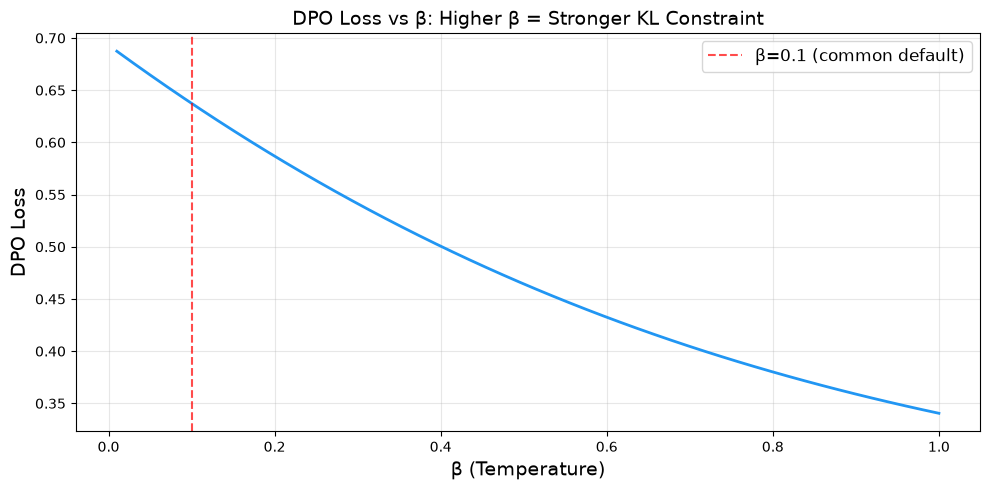

Plot saved as dpo_beta_sweep.png


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Sweep beta values
betas = np.linspace(0.01, 1.0, 50)
losses_per_beta = []

for b in betas:
    # Recompute without print statements
    chosen_lr = policy_chosen - ref_chosen
    rejected_lr = policy_rejected - ref_rejected
    logits_val = chosen_lr - rejected_lr
    l = -F.logsigmoid(b * logits_val).mean().item()
    losses_per_beta.append(l)

plt.figure(figsize=(10, 5))
plt.plot(betas, losses_per_beta, linewidth=2, color='#2196F3')
plt.xlabel('β (Temperature)', fontsize=14)
plt.ylabel('DPO Loss', fontsize=14)
plt.title('DPO Loss vs β: Higher β = Stronger KL Constraint', fontsize=14)
plt.grid(True, alpha=0.3)
plt.axvline(x=0.1, color='red', linestyle='--', alpha=0.7, label='β=0.1 (common default)')
plt.legend(fontsize=12)
plt.tight_layout()
plt.savefig('dpo_beta_sweep.png', dpi=100, bbox_inches='tight')
plt.show()
print("Plot saved as dpo_beta_sweep.png")

### 3.5 DPO with Real Model Log-Probs

Now let's combine our `compute_log_probs` function with the DPO loss, using our actual loaded models.

In [15]:
# In this demo, we use the instruct model as the Policy Model (pi_theta)
# and the base model as the Reference Model (pi_ref).
# (In real DPO, pi_ref is just a frozen copy of the initial pi_theta)
# Here we're just demonstrating the computation.

prompt = dpo_sample["prompt"]
chosen = dpo_sample["chosen"]
rejected = dpo_sample["rejected"]

# Compute log probs under both models
print("Computing log probabilities...")
pi_chosen, _ = compute_log_probs(model_instruct, tokenizer_instruct, prompt, chosen)
pi_rejected, _ = compute_log_probs(model_instruct, tokenizer_instruct, prompt, rejected)
ref_chosen_lp, _ = compute_log_probs(model_base, tokenizer_base, prompt, chosen)
ref_rejected_lp, _ = compute_log_probs(model_base, tokenizer_base, prompt, rejected)

print(f"\n=== Real Model Log-Probs ===")
print(f"Policy (Instruct) chosen:   {pi_chosen.item():.4f}")
print(f"Policy (Instruct) rejected: {pi_rejected.item():.4f}")
print(f"Ref    (Base)     chosen:   {ref_chosen_lp.item():.4f}")
print(f"Ref    (Base)     rejected: {ref_rejected_lp.item():.4f}")

# Compute DPO loss (need to unsqueeze to batch dimension)
print("\n=== DPO Loss Computation ===")
real_loss = dpo_loss(
    pi_chosen.unsqueeze(0),
    pi_rejected.unsqueeze(0),
    ref_chosen_lp.unsqueeze(0),
    ref_rejected_lp.unsqueeze(0),
    beta=0.1
)
print(f"\nReal DPO Loss: {real_loss.item():.6f}")

Computing log probabilities...

=== Real Model Log-Probs ===
Policy (Instruct) chosen:   -97.1250
Policy (Instruct) rejected: -111.8750
Ref    (Base)     chosen:   -100.3750
Ref    (Base)     rejected: -105.1875

=== DPO Loss Computation ===
  chosen_log_ratios:   tensor([3.2500], device='mps:0', dtype=torch.float16)
  rejected_log_ratios: tensor([-6.6875], device='mps:0', dtype=torch.float16)
  logits (before beta): tensor([9.9375], device='mps:0', dtype=torch.float16)
  scaled_logits:       tensor([0.9937], device='mps:0', dtype=torch.float16)
  per-sample losses:   tensor([0.3149], device='mps:0', dtype=torch.float16)

Real DPO Loss: 0.314941


---
## Section 4: GRPO Conceptual Demo

**Group Relative Policy Optimization (GRPO)** is used by DeepSeek-R1 to train reasoning models. Unlike DPO which uses human preferences, GRPO:

1. Generates multiple responses (a "group") for each prompt
2. Scores each response with a verifiable reward (e.g., math correctness)
3. Uses the group's mean reward as a baseline
4. Increases probability of above-average responses, decreases below-average ones

Let's implement a toy version.

In [16]:
def grpo_advantage_computation(rewards: torch.Tensor) -> torch.Tensor:
    """
    Compute GRPO advantages for a group of responses.
    
    GRPO uses the group mean as a baseline:
        advantage_i = (reward_i - mean(rewards)) / std(rewards)
    
    This eliminates the need for a learned value function (critic).
    
    Args:
        rewards: Shape [group_size] — rewards for each response in the group
    
    Returns:
        advantages: Shape [group_size] — normalized advantages
    """
    mean_reward = rewards.mean()      # Scalar — group baseline
    std_reward = rewards.std(unbiased=False) + 1e-8  # Scalar — for normalization (add epsilon for stability)
    
    advantages = (rewards - mean_reward) / std_reward  # Shape: [group_size]
    
    return advantages


# Simulate: Generate 8 responses to a math problem
# Reward = 1.0 if correct, 0.0 if incorrect, 0.5 if partially correct
print("=== GRPO Toy Example ===")
print("Prompt: 'What is 15% of 200?'")
print()

responses = [
    ("30",     1.0),   # Correct
    ("3000",   0.0),   # Wrong (multiplied instead of dividing)
    ("0.15 × 200 = 30", 1.0),   # Correct with work shown
    ("20",     0.0),   # Wrong
    ("15/100 * 200 = 30", 1.0), # Correct with formula
    ("About 30", 0.5), # Partially correct (hedging)
    ("25",     0.0),   # Wrong
    ("30.0",   1.0),   # Correct
]

rewards = torch.tensor([r for _, r in responses])  # Shape: [8]
advantages = grpo_advantage_computation(rewards)

print(f"{'Response':<25} {'Reward':>8} {'Advantage':>12}")
print("-" * 48)
for (resp, reward), adv in zip(responses, advantages):
    marker = "↑" if adv > 0 else "↓"
    print(f"{resp:<25} {reward:>8.1f} {adv.item():>+12.4f} {marker}")

print(f"\nGroup mean reward: {rewards.mean():.4f}")
print(f"Responses with positive advantage will have their probabilities INCREASED.")
print(f"Responses with negative advantage will have their probabilities DECREASED.")
print(f"\nThis is the key insight: GRPO uses the group itself as the baseline,")
print(f"so no separate reward model or value function is needed!")

=== GRPO Toy Example ===
Prompt: 'What is 15% of 200?'

Response                    Reward    Advantage
------------------------------------------------
30                             1.0      +0.9439 ↑
3000                           0.0      -1.2136 ↓
0.15 × 200 = 30                1.0      +0.9439 ↑
20                             0.0      -1.2136 ↓
15/100 * 200 = 30              1.0      +0.9439 ↑
About 30                       0.5      -0.1348 ↓
25                             0.0      -1.2136 ↓
30.0                           1.0      +0.9439 ↑

Group mean reward: 0.5625
Responses with positive advantage will have their probabilities INCREASED.
Responses with negative advantage will have their probabilities DECREASED.

This is the key insight: GRPO uses the group itself as the baseline,
so no separate reward model or value function is needed!


### 4.1 GRPO vs DPO: Key Differences

| Aspect | DPO | GRPO |
|--------|-----|------|
| Data | Human preference pairs (chosen vs rejected) | Self-generated groups with verifiable rewards |
| Reward | Implicit (learned from preferences) | Explicit (e.g., math correctness, code execution) |
| Baseline | Reference model | Group mean |
| Training signal | Binary (which is better) | Continuous (how much better) |
| Best for | General helpfulness, safety | Reasoning, math, code (verifiable tasks) |

---
## Cleanup

Let's free GPU memory.

In [17]:
# Clean up GPU memory
del model_base, model_instruct
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU memory freed. Current usage: {torch.cuda.memory_allocated() / (1024**3):.2f} GB")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    torch.mps.empty_cache()
    print("MPS memory freed.")
else:
    print("Cleanup complete.")

MPS memory freed.


## Summary

In this demo, we covered:

1. **Prompt Engineering:** Chat templates are not optional — they are the interface contract between you and the model. Zero-shot, few-shot, and CoT each trade tokens for accuracy.

2. **Base vs. Aligned Models:** Same architecture, same parameters, wildly different behavior. Alignment (SFT + DPO/RLHF) transforms a text completion engine into an instruction-following assistant.

3. **DPO Loss:** Directly optimizes the policy to prefer chosen over rejected responses, using the reference model as a KL-divergence anchor. The math is elegant: just log-probability ratios through a sigmoid.

4. **GRPO:** Uses group-relative advantages with verifiable rewards to train reasoning models without human preference data.

### Key Equation to Remember

$$\mathcal{L}_{DPO} = -\log \sigma\left(\beta \cdot \left(\underbrace{\log \frac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)}}_{\text{chosen log ratio}} - \underbrace{\log \frac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}}_{\text{rejected log ratio}}\right)\right)$$